# A/B Test: Effect of Ads on Conversion

## Imports

In [2]:
import sys

sys.path.append("..")
%load_ext autoreload
%autoreload 2

from src.stats import sample_size, sample_size_statsmodels, mde_value, srm_check, ztest_props
import duckdb
import matplotlib.pyplot as plt
import numpy as np
import statsmodels.formula.api as smf

rng = np.random.default_rng(52)

## Data Overview


### Dataset

In [3]:
duckdb.sql("""
    COPY (SELECT * FROM '../data/dataset.csv')
    TO '../data/criteo.parquet' (FORMAT parquet)
""")

duckdb.sql("SELECT * FROM '../data/criteo.parquet' LIMIT 10").show()

┌────────────────────┬────────────────────┬───────────────────┬───────────────────┬────────────────────┬───────────────────┬─────────────────────┬───────────────────┬────────────────────┬────────────────────┬───────────────────┬──────────────────────┬───────────┬────────────┬───────┬──────────┐
│         f0         │         f1         │        f2         │        f3         │         f4         │        f5         │         f6          │        f7         │         f8         │         f9         │        f10        │         f11          │ treatment │ conversion │ visit │ exposure │
│       double       │       double       │      double       │      double       │       double       │      double       │       double        │      double       │       double       │       double       │      double       │        double        │   int64   │   int64    │ int64 │  int64   │
├────────────────────┼────────────────────┼───────────────────┼───────────────────┼────────────────────┼────────

### Balance of the treatment distribution

In [4]:
duckdb.sql("SELECT 1.0*SUM(treatment)/COUNT(*) treatment FROM '../data/criteo.parquet'").show()

┌────────────────────┐
│     treatment      │
│       double       │
├────────────────────┤
│ 0.8500001287591226 │
└────────────────────┘



### Average visit/conversion/exposure

In [5]:
duckdb.sql("SELECT treatment, AVG(conversion), AVG(visit), AVG(exposure) FROM '../data/criteo.parquet' GROUP BY treatment").show()

┌───────────┬───────────────────────┬──────────────────────┬──────────────────────┐
│ treatment │   avg("conversion")   │      avg(visit)      │    avg(exposure)     │
│   int64   │        double         │        double        │        double        │
├───────────┼───────────────────────┼──────────────────────┼──────────────────────┤
│         0 │ 0.0019375880152813366 │  0.03820095691954503 │                  0.0 │
│         1 │ 0.0030894610674129645 │ 0.048543360048743316 │ 0.036036727482199896 │
└───────────┴───────────────────────┴──────────────────────┴──────────────────────┘



### Data Quality Checks

No missing values; no conversions without a visit.

In [6]:
duckdb.sql("SUMMARIZE '../data/criteo.parquet'").show()

┌─────────────┬─────────────┬─────────────────────┬──────────────────────┬───────────────┬──────────────────────┬──────────────────────┬──────────────────────┬──────────────────────┬──────────────────────┬──────────┬─────────────────┐
│ column_name │ column_type │         min         │         max          │ approx_unique │         avg          │         std          │         q25          │         q50          │         q75          │  count   │ null_percentage │
│   varchar   │   varchar   │       varchar       │       varchar        │     int64     │       varchar        │       varchar        │       varchar        │       varchar        │       varchar        │  int64   │  decimal(9,2)   │
├─────────────┼─────────────┼─────────────────────┼──────────────────────┼───────────────┼──────────────────────┼──────────────────────┼──────────────────────┼──────────────────────┼──────────────────────┼──────────┼─────────────────┤
│ f0          │ DOUBLE      │ 12.616364906986497  │ 26.74525

In [7]:
duckdb.sql("SELECT COUNT(CASE WHEN conversion = 1 AND visit = 0 THEN 1 END) FROM '../data/criteo.parquet'").show()

┌─────────────────────────────────────────────────────────────────────────────────┐
│ count(CASE  WHEN ((("conversion" = 1) AND (visit = 0))) THEN (1) ELSE NULL END) │
│                                      int64                                      │
├─────────────────────────────────────────────────────────────────────────────────┤
│                                                                               0 │
└─────────────────────────────────────────────────────────────────────────────────┘



## Experiment Design

### Sample Size Calculation

~13M users needed; the 2.5% gap comes from statsmodels using Cohen’s h (arcsine transform).

In [8]:
p_base = duckdb.sql("SELECT AVG(conversion) FROM '../data/criteo.parquet' WHERE treatment = 0").fetchone()[0]
print("Sample size from scratch: ", int(sample_size(p_base, 0.05)))
print("Sample size with solve_power: ", sample_size_statsmodels(p_base, 0.05))

Sample size from scratch:  12683927
Sample size with solve_power:  12998432


### MDE calculation

In [9]:
N = duckdb.sql("SELECT COUNT(*) FROM '../data/criteo.parquet'").fetchone()[0]
mde = mde_value(N, p_base)
print("Relative d_min: ", f"{mde:.2%}")

Relative d_min:  4.76%


### MDE Plotting

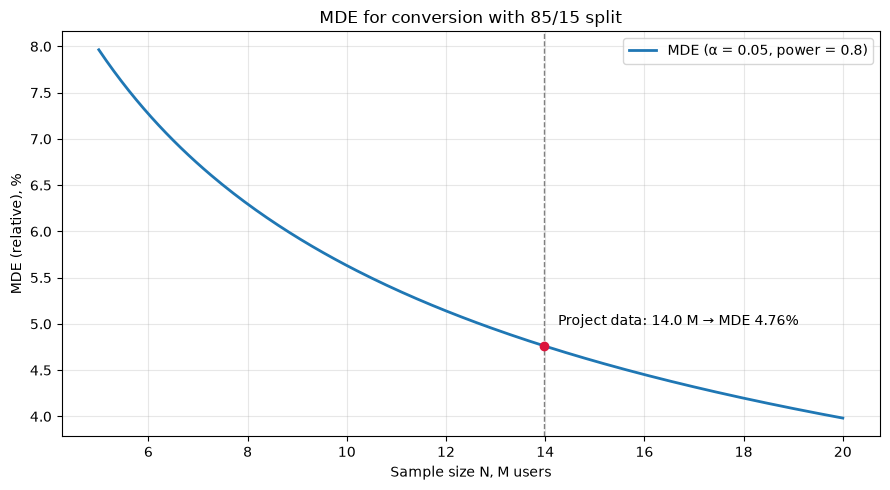

In [10]:
N_values = np.linspace(5_000_000, 20_000_000, num=200)
mde_values = mde_value(N_values, p_base)
our_mde = mde_value(N, p_base)

fig, ax = plt.subplots(figsize=(9, 5))

ax.plot(N_values / 1e6, mde_values * 100, linewidth=2, label="MDE (α = 0.05, power = 0.8)")

ax.axvline(N / 1e6, color="gray", linestyle="--", linewidth=1)
ax.scatter(N / 1e6, our_mde * 100, color="crimson", zorder=3)
ax.annotate(f"Project data: {N / 1e6:.1f} M → MDE {our_mde:.2%}",
            xy=(N / 1e6, our_mde * 100),
            xytext=(10, 15), textcoords="offset points")

ax.set_xlabel("Sample size N, M users")
ax.set_ylabel("MDE (relative), %")
ax.set_title("MDE for conversion with 85/15 split")
ax.grid(alpha=0.3)
ax.legend()

plt.tight_layout()
plt.show()

## Sanity Checks

### SRM check

No SRM `(p = 0.999)`. Note: the dataset is post-processed, so this check is not very informative.

In [ ]:
N_exp = duckdb.sql("SELECT COUNT(*) FROM '../data/criteo.parquet' WHERE treatment = 1").fetchone()[0]
N_cont = duckdb.sql("SELECT COUNT(*) FROM '../data/criteo.parquet' WHERE treatment = 0").fetchone()[0]

SE = (0.85 * 0.15 / (N_cont + N_exp)) ** 0.5
m = 1.96 * SE
print("p_exp in interval: ", 0.85 + m >= N_exp/(N_cont + N_exp) >= 0.85 - m)

stat, p_value, is_srm = srm_check(N_exp, N_cont)
print(f"chi2 = {stat:.6f}, p-value = {p_value:.4f}, SRM: {is_srm}")

9.55009835011573e-05
p_exp in interval:  True
chi2 = 0.000002, p-value = 0.9989, SRM: False


### SMD

All `|SMD| < 0.05` — groups are balanced by the usual threshold.

In [12]:
duckdb.sql("""
WITH long AS (
    UNPIVOT '../data/criteo.parquet'
    ON f0, f1, f2, f3, f4, f5, f6, f7, f8, f9, f10, f11
    INTO NAME feature VALUE val
)
SELECT
    feature,
    (AVG(val) FILTER (WHERE treatment = 1) - AVG(val) FILTER (WHERE treatment = 0))
    / SQRT(
        (VAR_SAMP(val) FILTER (WHERE treatment = 1) + VAR_SAMP(val) FILTER (WHERE treatment = 0)) / 2
      ) AS smd
FROM long
GROUP BY feature
ORDER BY feature
""").show()

┌─────────┬────────────────────────┐
│ feature │          smd           │
│ varchar │         double         │
├─────────┼────────────────────────┤
│ f0      │  -0.006865619171152977 │
│ f1      │   0.023994397637629117 │
│ f10     │   0.010563463264447428 │
│ f11     │ -0.0051595283149506455 │
│ f2      │  -0.006240989431270101 │
│ f3      │  -0.048836340185876084 │
│ f4      │   0.007965661179671027 │
│ f5      │  -0.030556830945976318 │
│ f6      │   -0.04044806881194132 │
│ f7      │    0.02126953009281645 │
│ f8      │  -0.022433335241706005 │
│ f9      │   0.024001057696809967 │
└─────────┴────────────────────────┘
  12 rows                2 columns



## Treatment Effect Estimation

### Z-test for conversion

In [13]:
p_t = duckdb.sql("SELECT AVG(conversion) FROM '../data/criteo.parquet' WHERE treatment = 1").fetchone()[0]
n_t = duckdb.sql("SELECT COUNT(*) FROM '../data/criteo.parquet' WHERE treatment = 1").fetchone()[0]
p_c = duckdb.sql("SELECT AVG(conversion) FROM '../data/criteo.parquet' WHERE treatment = 0").fetchone()[0]
n_c = duckdb.sql("SELECT COUNT(*) FROM '../data/criteo.parquet' WHERE treatment = 0").fetchone()[0]
print("Z-test for conversion:")
print(*(f"{k}: {v}" for k, v in ztest_props(p_t, n_t, p_c, n_c).items()), sep="\n")

Z-test for conversion:
p_t: 0.0030894610674129645
p_c: 0.0019375880152813366
diff: 0.0011518730521316279
se: 4.03931711188182e-05
ci: (np.float64(0.0010727038915173807), np.float64(0.001231042212745875))
z: 28.516529408977203
p_value: 0.0


### Z-test for visit

In [14]:
p_t_visit = duckdb.sql("SELECT AVG(visit) FROM '../data/criteo.parquet' WHERE treatment = 1").fetchone()[0]
n_t_visit = duckdb.sql("SELECT COUNT(*) FROM '../data/criteo.parquet' WHERE treatment = 1").fetchone()[0]
p_c_visit = duckdb.sql("SELECT AVG(visit) FROM '../data/criteo.parquet' WHERE treatment = 0").fetchone()[0]
n_c_visit = duckdb.sql("SELECT COUNT(*) FROM '../data/criteo.parquet' WHERE treatment = 0").fetchone()[0]
print("Z-test for visit")
print(*(f"{k}: {v}" for k, v in ztest_props(p_t_visit, n_t_visit, p_c_visit, n_c_visit).items()), sep="\n")

Z-test for visit
p_t: 0.048543360048743316
p_c: 0.03820095691954503
diff: 0.010342403129198284
se: 0.0001585105068283582
ci: (np.float64(0.010031728244643512), np.float64(0.010653078013753056))
z: 65.24742956249247
p_value: 0.0


### Parametric Bootstrap CI

In [15]:
p_t_bs = rng.binomial(n_t, p_t, size=1000) / n_t
p_c_bs = rng.binomial(n_c, p_c, size=1000) / n_c
diff_bs = p_t_bs - p_c_bs
print("Bootstrap 95% CI for conversion:", np.percentile(diff_bs, [2.5, 97.5]))

lift_bs = diff_bs / p_c_bs
print("Bootstrap 95% CI for conversion (lift):", np.percentile(lift_bs, [2.5, 97.5]))

Bootstrap 95% CI for conversion: [0.00107832 0.00121612]
Bootstrap 95% CI for conversion (lift): [0.53965286 0.64664755]


## Variance Reduction (Regression Adjustment)

In [16]:
df_cuped = duckdb.sql("""
    SELECT f0, f1, f2, f3, f4, f5, f6, f7, f8, f9, f10, f11, treatment, conversion
    FROM '../data/criteo.parquet'
    USING SAMPLE reservoir(2000000 ROWS) REPEATABLE (52)
""").df()

tr_nf = smf.ols("conversion ~ treatment", data=df_cuped).fit(cov_type="HC1")
tr_f = smf.ols("conversion ~ treatment + f0 + f1 + f2 + f3 + f4 + f5 + f6 + f7 + f8 + f9 + f10 + f11", data=df_cuped).fit(cov_type="HC1")
tau_nf, se_nf, tau_f, se_f = tr_nf.params["treatment"], tr_nf.bse["treatment"], tr_f.params["treatment"], tr_f.bse["treatment"]

print("Effect tau for featureless:", tau_nf, "Effect tau for featured:", tau_f, f"Decrease by: {1 - tau_f / tau_nf:.1%}")
print("SE for featureless:", se_nf, "SE for featured:", se_f, f"Decrease by: {1 - se_f / se_nf:.1%}%")

Effect tau for featureless: 0.0012802121204233043 Effect tau for featured: 0.001017749109176295 Decrease by: 20.5%
SE for featureless: 8.946359698466567e-05 SE for featured: 8.341926136244573e-05 Decrease by: 6.8%%


## Conclusion

- ~14M users give MDE ≈ 4.8% (α = 0.05, power = 0.8). No SRM, all features balanced (|SMD| < 0.05).
- Ads increase conversion from 0.194% to 0.309%: **+0.115 p.p. (+59%)**, 95% CI [0.107; 0.123] p.p., p < 0.001. The bootstrap CI is ~15% narrower because it reflects the unpooled SE, while the z-test CI uses the pooled SE (which assumes H0); both lead to the same conclusion.
- Regression adjustment narrows the SE by 6.8% and lowers the estimate by ~20% (on a 2M subsample).
- **Decision:** the effect is significant and well above MDE → ads are worth showing.